# 06 · Decision Framework

> **The practical guide.** What to do now that you know the model sees tokens:
> the vocab-size trade-off, a decision checklist, and the shipped from-scratch
> library you can reuse.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## The vocabulary-size trade-off

In [2]:
from src.bpe import BPETokenizer, train_bpe
from src.datasets.corpora import training_corpus

corpus = training_corpus(60_000)
heldout = "the model reads learned tokens rather than the individual letters of a word"

sizes = [256, 320, 512, 768, 1024, 1536]
study = []
for vs in sizes:
    merges, vocab = train_bpe(corpus, vocab_size=vs)
    tok = BPETokenizer(merges, vocab)
    n = len(tok.encode(heldout))
    study.append({"vocab_size": len(vocab), "merges": len(merges), "heldout_tokens": n})
    print(f"vocab {len(vocab):>5}  ->  {n} tokens on held-out text")

print("saved:", save_json("06_vocab_tradeoff", study))

vocab   256  ->  75 tokens on held-out text


vocab   320  ->  40 tokens on held-out text


vocab   512  ->  27 tokens on held-out text


vocab   768  ->  26 tokens on held-out text


vocab  1024  ->  26 tokens on held-out text


vocab  1477  ->  26 tokens on held-out text
saved: /workspaces/tokenization_101/outputs/data/06_vocab_tradeoff.json


saved: /workspaces/tokenization_101/outputs/figures/06_vocab_tradeoff.png


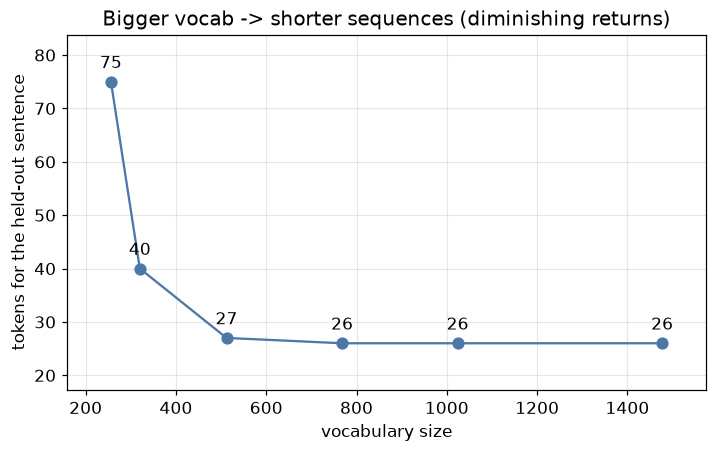

In [3]:
xs = [s["vocab_size"] for s in study]
ys = [s["heldout_tokens"] for s in study]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(xs, ys, marker="o", markersize=7, color="#4C78A8")
for x, y in zip(xs, ys):
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 9), ha="center")
ax.set_xlabel("vocabulary size")
ax.set_ylabel("tokens for the held-out sentence")
ax.set_title("Bigger vocab -> shorter sequences (diminishing returns)")
ax.margins(x=0.08, y=0.18)
ax.grid(True, alpha=0.3)
print("saved:", save_figure(fig, "06_vocab_tradeoff"))
plt.show()

## The checklist

1. **The model sees tokens.** Never ask it to operate on characters it cannot
   see (spelling, reversing, counting letters) without a tool or character view.
2. **Distrust raw multi-digit arithmetic.** Route it to a calculator.
3. **Budget tokens, not words.** Measure the per-language tax before scoping.
4. **Choose vocab size as a trade-off:** larger -> shorter sequences but more
   embedding parameters and worse rare-token handling.
5. **Know when it matters:** cost, context limits, multilingual, character-level
   tasks, and code. Otherwise the default is fine.

In [4]:
checklist = {
    "model_sees_tokens": "Never ask the model to operate on characters it cannot see (spelling, reversing, counting) without a tool or a character-level view.",
    "arithmetic": "Distrust raw multi-digit arithmetic; route it to a calculator or use digit-level handling.",
    "budget_tokens": "Budget tokens, not words; measure the per-language tax before scoping multilingual work.",
    "vocab_size": "Larger vocab -> shorter sequences but more embedding parameters and worse rare-token handling.",
    "when_it_matters": "Tokenization matters most for cost, context limits, multilingual, character-level tasks, and code.",
}
print("saved:", save_json("06_checklist", checklist))

saved: /workspaces/tokenization_101/outputs/data/06_checklist.json


## The shipped library, end to end

In [5]:
from src.bpe import BPETokenizer
from src.datasets.corpora import training_corpus
from src.probes.spelling import probe_spelling

tok = BPETokenizer().train(training_corpus(40_000), vocab_size=512)
print("pieces of 'strawberry':", tok.pieces("strawberry"))
print("round-trip:", tok.decode(tok.encode("hello")) == "hello")
print("characters visible:", probe_spelling(tok, "strawberry").characters_visible)

pieces of 'strawberry': ['st', 'r', 'a', 'w', 'b', 'er', 'r', 'y']
round-trip: True
characters visible: False


**You now have the whole picture:** text is not characters, BPE is ~50 lines,
and that one preprocessing choice explains spelling, arithmetic, and the
language tax. Reuse `src/` for your own corpora and tokenizers.